In [1]:
import pathlib

import navis.interfaces.neuprint as neu
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd
from el_hd_plasticity.connectomics.run_epg_postsynapse_distance import get_epg_er_synapses

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_epg_postsynapse_distance
client = cn.npt_client()

ER_TYPE = 'ER4d'                                  # the type shown in the example plots
HEMISPHERE_COLORS = {'R': plt.cm.cool(.7), 'L': plt.cm.cool(0.)}      # the two ends of 'cool': magenta, cyan


## Distance between the ER inputs an EPG neuron receives

The postsynaptic counterpart of `epg_instance_synapse_distance.ipynb`. There the distances were measured along the *presynaptic* ER
neuron; here they are measured along the *postsynaptic* EPG neuron. For every ER->EPG synapse (at its postsynaptic site on the EPG
neuron) we take the cable distance along the EPG neuron to the nearest other ER->EPG synapse of a different group, computed by
`python -m el_hd_plasticity.connectomics.run_epg_postsynapse_distance`. Every comparison stays within one ER type; the example
plots show ER4d and the distance sections cover all 21 types.

Two groupings:

- **source** -- the nearest input from *any other ER neuron* of the type.
- **hemisphere** -- the ER neuron's hemisphere (`ER4d(ring)_L` vs `ER4d(ring)_R`). With only two groups this is the nearest input from
  an ER neuron of the *other* hemisphere.

The hypothesis: a learning signal at an EL input is more robust presynaptically. Second-messenger diffusion within the ER neuron
should matter less, because the ER synapses near each other carry the same information. Postsynaptically, diffusion within the EPG
dendrite could instead produce crosstalk between ER->EPG synapses that encode different landmark orientations. Short distances here,
relative to the presynaptic ones, are what that crosstalk would require.

Paths are not length-limited; the histograms use the 0-16 micron scale and bins of the other distance analyses.

### EPG and ER4d arbors in the EB

Where the two cell types meet, with the view cropped to the ellipsoid body: every EPG arbor in grey and
every ER4d arbor over it, colored by the hemisphere its ER neuron comes from. The ER4d neurons of both
hemispheres tile the same outer annulus, so an EPG dendrite there is in reach of inputs from either side --
which is what the distances below measure.

In [2]:
ebcoords = cn.EBCoordinateSystem()
eb = ebcoords.fetch_roi('EB')

syns, epgs = get_epg_er_synapses(ER_TYPE)
example_epg = syns['bodyId_post'].value_counts().index[0]        # the EPG receiving most ER4d synapses
epg_skeleton = ebcoords.fetch_skeleton(example_epg)

epg_syns = cn.add_eb_coords(syns.loc[syns['bodyId_post'] == example_epg].copy(), ebcoords, type='post')
print(f'{example_epg}: {len(epg_syns)} {ER_TYPE} synapses from {epg_syns["source"].nunique()} ER neurons',
      epg_syns['hemisphere'].value_counts().to_dict())


/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:266: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (20 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

1168664495: 371 ER4d synapses from 25 ER neurons {'R': 211, 'L': 160}


Fetching:   0%|          | 0/25 [00:00<?, ?it/s]

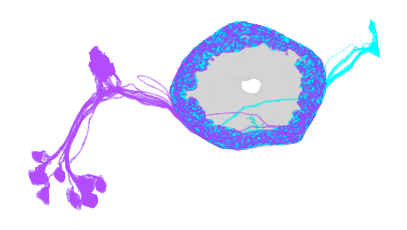

In [6]:
ers, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type=ER_TYPE))
# epg_arbors = ebcoords.fetch_skeletons(epgs['bodyId'])
er_arbors = ebcoords.fetch_skeletons(ers['bodyId'])
er_hemisphere = sd.instance_hemisphere(ers['instance'])
# print(f'{len(epg_arbors)} EPG, {len(er_arbors)} {ER_TYPE}')

fig, ax = plotting.plot_neurons_2d([eb], colors=plt.cm.Greys(.3), alpha=.7, radius=False)
# plotting.plot_neurons_2d(list(epg_arbors), colors=[plt.cm.Greys(.75)] * len(epg_arbors),
                        #  alpha=.25, ax=ax)
for skeleton, side in zip(er_arbors, er_hemisphere, strict=True):
    plotting.plot_neurons_2d([skeleton], colors=HEMISPHERE_COLORS[side], alpha=.35,
                              ax=ax)

vertices = np.asarray(eb.vertices)                      # the view, not the neurons, is cropped to the EB
# ax.set_xlim(vertices[:, 0].min()-5000, vertices[:, 0].max()+5000)
# ax.set_ylim(vertices[:, 1].min()-1500, vertices[:, 1].max()+1500)

keys = [ax.plot([], [], color=plt.cm.Greys(.75), linewidth=3, label='EPG')[0]]
keys += [ax.plot([], [], color=color, linewidth=3, label=f'{ER_TYPE} {side}')[0]
         for side, color in HEMISPHERE_COLORS.items()]
# ax.legend(handles=keys, loc='upper left', bbox_to_anchor=(1., 1.), frameon=False)
fig.savefig(figfolder / f'epg_{ER_TYPE}_eb_arbors.png', dpi=500, transparent=True, bbox_inches='tight')

### Example EPG dendrite

Version 1, by source: the three ER neurons whose synapses onto this EPG lie closest together (the same selection as the
presynaptic examples).

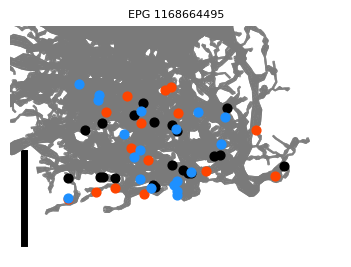

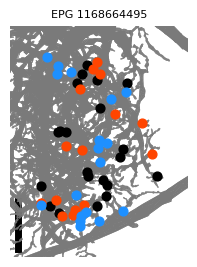

In [4]:
epg_syns['type'] = epg_syns['source']
sources = sd.adjacent_instances(epg_syns)

for plane in ('xy', 'xz'):
    fig, ax = plotting.plot_instance_example(epg_skeleton, epg_syns, sources, view=tuple(plane),
                                             skeleton_color=plt.cm.Greys(.6))
    ax.set_title(f'EPG {example_epg}', fontsize=8)
    fig.savefig(figfolder / f'epg_post_source_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')


Version 2, by hemisphere of the ER neuron.

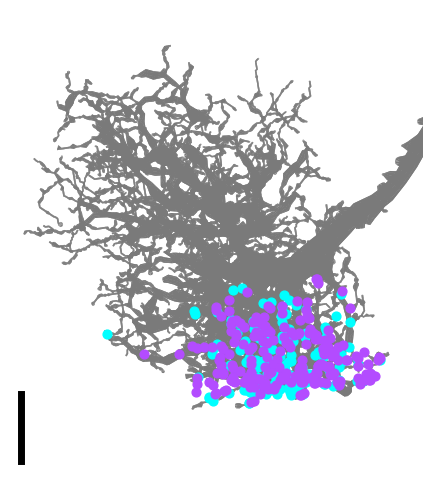

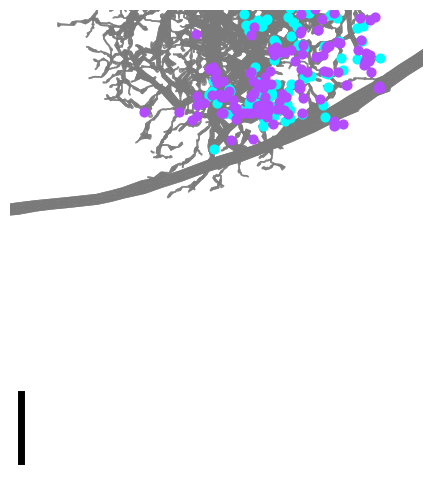

In [16]:
epg_syns['type'] = epg_syns['hemisphere']

for plane in ('xy', 'xz'):
    fig, ax = plotting.plot_instance_example(epg_skeleton, epg_syns, sd.HEMISPHERES, view=tuple(plane),
                                             colors=[HEMISPHERE_COLORS[side] for side in sd.HEMISPHERES],
                                             skeleton_color=plt.cm.Greys(.6), legend=False, figsize=[10,6])
    # ax.set_title(f'EPG {example_epg}', fontsize=8)
    fig.savefig(figfolder / f'epg_post_hemisphere_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')


### Distances

The distances of every ER type, with the presynaptic analysis of the same synapses (`epg_instance_synapse_distance.ipynb`) alongside.

In [6]:
GROUPINGS = ('source', 'hemisphere')

post_df = pd.concat([sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES, name=f'post_{grouping}',
                                                     filename=f'{{type}}_epg_post_{grouping}_distances.pkl')
                     for grouping in GROUPINGS], ignore_index=True)

# the presynaptic analysis of the same synapses, for comparison
pre_df = sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES, name='pre_column')
distance_df = pd.concat([pre_df, post_df], ignore_index=True)

summary = distance_df.pivot_table(index='er', columns='source', values='distances', aggfunc='median')
print(summary.loc[list(sd.ER_TYPES), ['pre_column', 'post_source', 'post_hemisphere']].round(2))


source  pre_column  post_source  post_hemisphere
er                                              
ER4d         13.62         0.81             1.23
ER4m          2.86         1.11             1.88
ER2_a         6.70         2.19             3.44
ER2_b         3.12         2.63             4.02
ER2_c         8.01         0.99             1.60
ER2_d         5.65         2.84             4.06
ER3w_b        1.18         1.04             1.69
ER3a_c        3.99         4.05             9.55
ER3p_a        0.92         0.72             1.15
ER3w_a        1.72         1.48             2.28
ER3a_b       27.74        20.25            20.25
ER3p_b        1.61         0.97             1.52
ER3d_c        6.06         1.23             2.11
ER3d_a        6.20         0.98             1.58
ER3d_d        6.78         1.27             2.11
ER3d_b        5.36         0.89             1.46
ER3a_a        8.00         2.13             4.89
ER3a_d       38.80        16.28            16.28
ER3m          2.67  

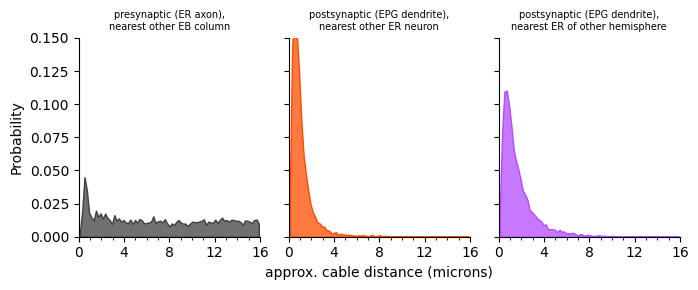

In [7]:
SOURCES = ('pre_column', 'post_source', 'post_hemisphere')
LABELS = {'pre_column': 'presynaptic (ER axon),\nnearest other EB column',
          'post_source': 'postsynaptic (EPG dendrite),\nnearest other ER neuron',
          'post_hemisphere': 'postsynaptic (EPG dendrite),\nnearest ER of other hemisphere'}
SHORT = {'pre_column': 'pre: other EB column', 'post_source': 'post: other ER neuron',
         'post_hemisphere': 'post: ER of other hemisphere'}
COLORS = (plt.cm.Greys(.8), plt.cm.autumn(.3), plt.cm.cool(.7))

example = distance_df.loc[distance_df['er'] == ER_TYPE]
fig, axs = plt.subplots(1, 3, figsize=(7, 3), sharey=True)
for ax, source, color in zip(axs, SOURCES, COLORS, strict=True):
    plotting.plot_family_distance_histogram(example, (ER_TYPE,), source=source, color=color, ax=ax)
    ax.set_title(LABELS[source], fontsize=7)
    ax.set_xlabel('')
axs[1].set_xlabel('approx. cable distance (microns)')          # one label for the three panels
fig.tight_layout()
fig.savefig(figfolder / f'{ER_TYPE}_epg_post_dist.pdf', bbox_inches='tight')


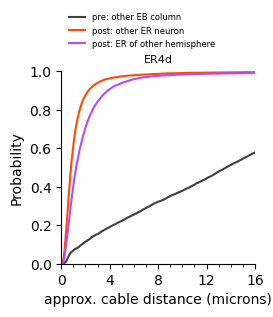

In [8]:
fig, ax = plotting.plot_distance_ecdf(example, SOURCES, labels=SHORT, colors=COLORS)
ax.set_title(ER_TYPE, fontsize=8)
ax.legend(fontsize=6, loc='lower left', bbox_to_anchor=(0, 1.08), frameon=False)
fig.savefig(figfolder / f'{ER_TYPE}_epg_post_dist_cumulative.pdf', bbox_inches='tight')


### Every ER type

One panel per ER family: the presynaptic distance of its synapses (grey) against the two postsynaptic ones. A curve that ends below 1
at the right edge has that fraction of its synapses beyond 16 microns.

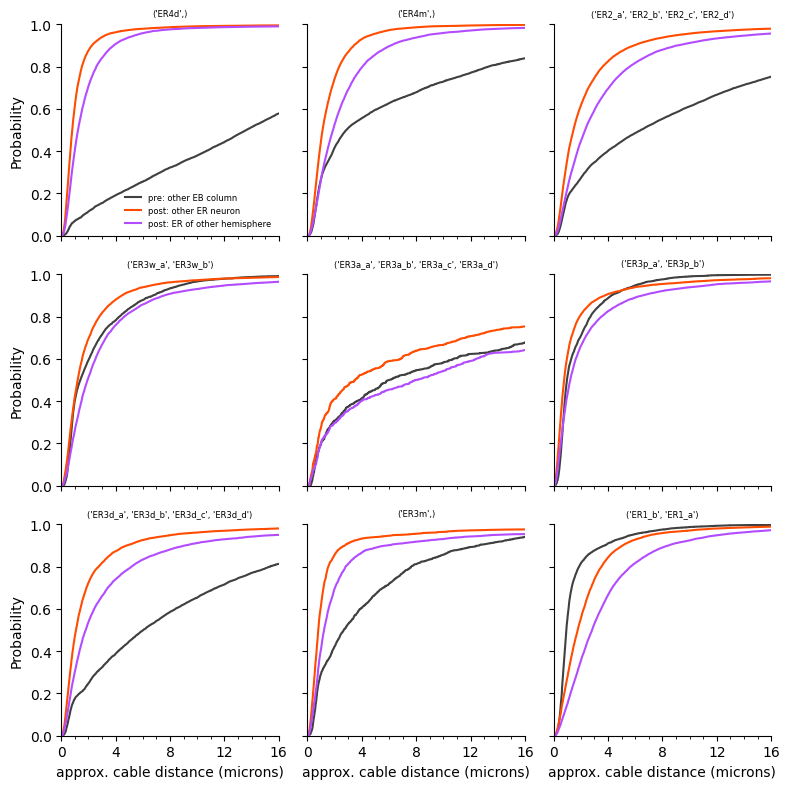

In [9]:
fig, axs = plt.subplots(3, 3, figsize=(8, 8), sharex=True, sharey=True)
for ax, group in zip(axs.flat, sd.ER_GROUPS, strict=True):
    plotting.plot_distance_ecdf(distance_df.loc[distance_df['er'].isin(group)], SOURCES, labels=SHORT, colors=COLORS, ax=ax)
    ax.set_title(str(group), fontsize=6)
for ax in axs.flat[:-3]:
    ax.set_xlabel('')
for ax in axs[:, 1:].flat:
    ax.set_ylabel('')
axs.flat[0].legend(fontsize=6, loc='lower right', frameon=False)
fig.tight_layout()
fig.savefig(figfolder / 'all_epg_post_dist_cumulative.pdf', bbox_inches='tight')


Median distance of every ER type, presynaptic against postsynaptic.

presynaptic median / the longer postsynaptic median:
er
ER4d      11.1
ER4m       1.5
ER2_a      1.9
ER2_b      0.8
ER2_c      5.0
ER2_d      1.4
ER3w_b     0.7
ER3a_c     0.4
ER3p_a     0.8
ER3w_a     0.8
ER3a_b     1.4
ER3p_b     1.1
ER3d_c     2.9
ER3d_a     3.9
ER3d_d     3.2
ER3d_b     3.7
ER3a_a     1.6
ER3a_d     2.4
ER3m       2.2
ER1_b      0.3
ER1_a      0.4


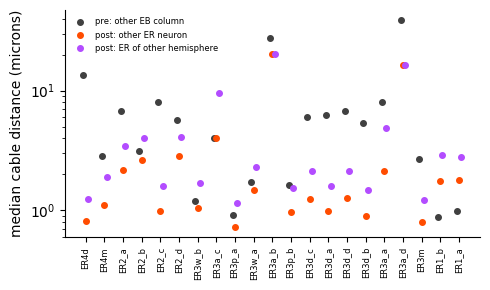

In [10]:
medians = summary.loc[list(sd.ER_TYPES), list(SOURCES)]

fig, ax = plt.subplots(figsize=(5, 3))
for i, (source, color) in enumerate(zip(SOURCES, COLORS, strict=True)):
    ax.plot(np.arange(len(medians)) + .12 * (i - 1), medians[source], 'o', color=color, label=SHORT[source], markersize=4)
ax.set_xticks(np.arange(len(medians)))
ax.set_xticklabels(medians.index, rotation=90, fontsize=6)
ax.set_ylabel('median cable distance (microns)')
ax.set_yscale('log')
ax.legend(fontsize=6, frameon=False)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(figfolder / 'all_epg_post_median_distance.pdf', bbox_inches='tight')

ratio = medians['pre_column'] / medians[['post_source', 'post_hemisphere']].max(axis=1)
print('presynaptic median / the longer postsynaptic median:')
print(ratio.round(1).to_string())
